# Topic 1: What Is an Outlier?

## Step 1: Understand the Concept

An **outlier** is a data point that differs significantly from most other observations in a dataset.

Outliers may occur because of data-entry errors, measurement errors, unusual events, or genuine variations in the data.

### Why Is Outlier Identification Important?

- To understand unusual values in a dataset.
- To identify possible data-quality issues.
- To understand unusual business activities.
- To determine whether unusual observations affect statistical analysis.
- To prepare reliable data for Machine Learning.

An unusual value is not always incorrect. Each potential outlier should be investigated before deciding whether to remove, transform, or retain it.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following product quantities:

| Observation | Quantity |
|---|---:|
| 1 | 2 |
| 2 | 3 |
| 3 | 4 |
| 4 | 5 |
| 5 | 100 |

The value 100 is much larger than the other quantities and may be an outlier.

### Real-World Example

A shop usually sells a few products per transaction, but one customer purchases 100 products. This transaction may be unusual, but it could be genuine.

### Business Example

A retail analyst investigates unusually large product quantities to determine whether they represent bulk purchases or incorrect records.

### AI/ML Use Case

Outliers can affect statistical summaries and some Machine Learning models. Identifying them helps analysts decide how to prepare data appropriately.

### Importance

Outlier detection is the first step in understanding unusual observations. Statistical methods can flag potential outliers, but business context is needed to interpret them.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "online_retail_II.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Quantity Summary:


count    525461.000000
mean         10.337667
std         107.424110
min       -9600.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       19152.000000
Name: Quantity, dtype: float64

Smallest Quantity Values:


303996   -9600
507225   -9360
156488   -9200
194372   -9000
428975   -9000
437008   -8800
359669   -7128
258814   -7100
359670   -7008
269558   -7000
Name: Quantity, dtype: int64

Largest Quantity Values:


90857     19152
127166    12960
127168    12960
127169    12744
127167    12480
192197    10200
135027    10000
135028    10000
135029    10000
135030    10000
Name: Quantity, dtype: int64

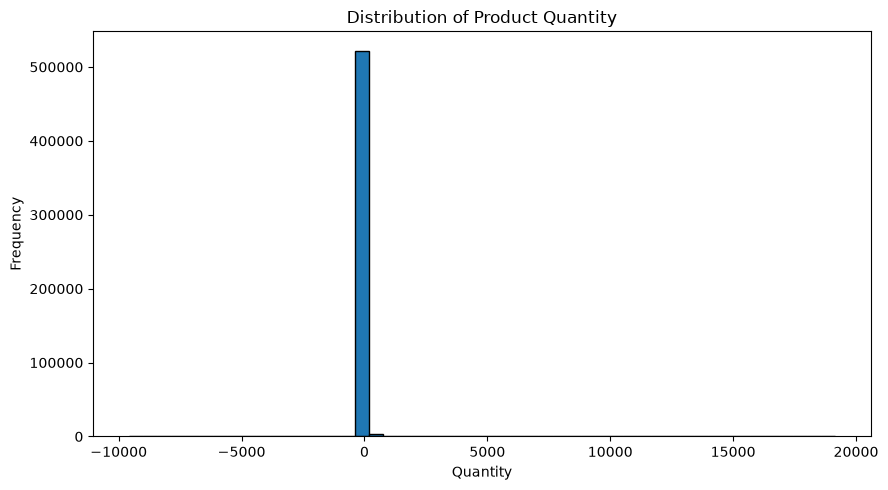

In [7]:
# Step 3: Implement the Concept

# Select the Quantity column and remove missing values
quantity_data = pd.to_numeric(
    df["Quantity"], errors="coerce"
).dropna()

# Display basic statistics
print("Quantity Summary:")
display(quantity_data.describe())

# Display the smallest and largest quantity values
print("Smallest Quantity Values:")
display(quantity_data.nsmallest(10))

print("Largest Quantity Values:")
display(quantity_data.nlargest(10))

# Visualize the distribution
plt.figure(figsize=(9, 5))
plt.hist(quantity_data, bins=50, edgecolor="black")
plt.title("Distribution of Product Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Quantity Column

`df["Quantity"]` selects the product quantity values from the retail dataset.

### 2. Convert Values to Numeric

`pd.to_numeric(errors="coerce")` converts valid values to numbers and turns invalid values into missing values.

`dropna()` removes missing values from this analysis.

### 3. Display Summary Statistics

`describe()` provides the count, mean, standard deviation, minimum, quartiles, and maximum.

### 4. Inspect Extreme Values

`nsmallest(10)` displays the ten smallest values, while `nlargest(10)` displays the ten largest values.

These values help us investigate unusual observations but do not confirm that they are outliers.

### 5. Plot the Distribution

`plt.hist()` creates a histogram showing how frequently different quantity values occur.

### Where It Is Used in AI/ML or Data Analytics

Initial outlier inspection helps analysts understand the distribution of a feature before applying formal detection methods such as IQR or Z-Score.

### Observation

After running the code, record:

- What are the minimum and maximum Quantity values?
- Are most values concentrated within a particular range?
- Are any values unusually far from the majority?
- Why should unusual values be investigated before removing them?

Base your observations on the actual output and histogram.

# Topic 2: Why Outliers Occur

## Step 1: Understand the Concept

Outliers can occur for different reasons. An outlier is not always an error; it may represent a genuine and unusual observation.

### Common Reasons for Outliers

1. **Data Entry Errors:** Incorrect values entered into the dataset, such as typing 500 instead of 50.
2. **Measurement Errors:** Errors caused by faulty measuring devices or inaccurate data collection.
3. **Natural Variation:** Genuine differences between observations, such as customers purchasing different quantities.
4. **Rare Events:** Unusual events, such as a customer placing a very large bulk order.
5. **Different Groups:** Combining different types of customers or products may create values that look unusual compared with the overall dataset.

### Why Is This Important?

Understanding the reason for an outlier helps us decide whether to correct, remove, transform, or retain the value during data preprocessing.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following product quantities:

| Customer | Quantity | Possible Reason |
|---|---:|---|
| A | 2 | Normal purchase |
| B | 4 | Normal purchase |
| C | 5 | Normal purchase |
| D | 500 | Bulk purchase or data-entry error |

The value 500 is unusual compared with the other values. However, we need more information before deciding whether it is incorrect.

### Real-World Example

A customer may purchase hundreds of products for a shop. This large quantity may be genuine and should not automatically be removed.

### Business Example

An online retail company may receive a bulk order from a business customer. Investigating the order helps the company understand customer purchasing behavior.

### AI/ML Use Case

Outlier investigation helps improve data quality before training machine learning models. Incorrect extreme values can affect statistical summaries and some model predictions.

### Important Rule

Always investigate the reason for an unusual value before deciding how to handle it.

In [8]:
# Step 3: Implement the Concept

# Select Quantity and Price columns
outlier_reason_data = df[["Quantity", "Price"]].copy()

# Convert columns to numeric values
outlier_reason_data["Quantity"] = pd.to_numeric(
    outlier_reason_data["Quantity"], errors="coerce"
)

outlier_reason_data["Price"] = pd.to_numeric(
    outlier_reason_data["Price"], errors="coerce"
)

# Display the smallest and largest Quantity values
print("Smallest Quantity Values:")
display(outlier_reason_data["Quantity"].nsmallest(10))

print("Largest Quantity Values:")
display(outlier_reason_data["Quantity"].nlargest(10))

# Display the smallest and largest Price values
print("Smallest Price Values:")
display(outlier_reason_data["Price"].nsmallest(10))

print("Largest Price Values:")
display(outlier_reason_data["Price"].nlargest(10))

# Display rows with unusually high quantities
print("Rows with Quantity greater than 100:")
display(
    outlier_reason_data[
        outlier_reason_data["Quantity"] > 100
    ].head(10)
)

Smallest Quantity Values:


303996   -9600
507225   -9360
156488   -9200
194372   -9000
428975   -9000
437008   -8800
359669   -7128
258814   -7100
359670   -7008
269558   -7000
Name: Quantity, dtype: int64

Largest Quantity Values:


90857     19152
127166    12960
127168    12960
127169    12744
127167    12480
192197    10200
135027    10000
135028    10000
135029    10000
135030    10000
Name: Quantity, dtype: int64

Smallest Price Values:


179403   -53594.36
276274   -44031.79
403472   -38925.87
263           0.00
283           0.00
284           0.00
470           0.00
3114          0.00
3161          0.00
3162          0.00
Name: Price, dtype: float64

Largest Price Values:


241824    25111.09
241827    25111.09
320581    18910.69
517953    13541.33
517955    13541.33
519294    13541.33
519170    13474.79
135012    10953.50
135013    10953.50
135014    10953.50
Name: Price, dtype: float64

Rows with Quantity greater than 100:


,Quantity,Price
217,576,0.21
223,288,0.21
282,160,1.45
575,800,1.45
934,160,2.55
935,160,2.55
937,192,1.45
943,144,0.85
950,180,0.21
951,216,0.85


## Code Explanation

### 1. Select the Columns

`df[["Quantity", "Price"]].copy()` selects the two numerical columns needed for investigation.

### 2. Convert Values to Numeric

`pd.to_numeric(errors="coerce")` converts valid values to numbers and replaces invalid values with missing values.

### 3. Inspect Extreme Values

- `nsmallest(10)` displays the 10 smallest values.
- `nlargest(10)` displays the 10 largest values.
- Filtering `Quantity > 100` helps inspect high-quantity transactions.

### 4. Interpret the Results

A high quantity or price may be caused by a data-entry error, a genuine bulk purchase, or an unusual product transaction. The code identifies values for investigation; it does not prove that they are outliers.

### Where It Is Used in AI/ML or Data Analytics

Outlier investigation is used during data cleaning and exploratory data analysis to identify suspicious values and understand unusual customer or transaction behavior.

### Observation

After running the code, record one unusual value and a possible reason it needs investigation. Do not remove it without checking the available evidence.

# Topic 3: Types of Outliers

## Step 1: Understand the Concept

Outliers can be classified into different types based on how unusual values appear in a dataset.

### 1. Point Outlier

A single observation that is very different from most other observations.

Example: Product quantities are 2, 3, 4, 5, and 500. The value 500 may be a point outlier.

### 2. Contextual Outlier

A value that is unusual in a specific context but may be normal in another context.

Example: Selling 100 products in one day may be unusual for a small shop but normal during a major sale.

### 3. Collective Outlier

A group of observations that becomes unusual when considered together, even if individual values do not look unusual.

Example: A series of unusual transactions occurring together may indicate suspicious purchasing activity.

### Why Is Classification Important?

Identifying the type of outlier helps analysts understand whether a value is unusual on its own, unusual in a particular situation, or unusual as part of a group.

## Step 2: Demonstrate the Concept

### Simple Example

| Quantity | Possible Type | Explanation |
|---:|---|---|
| 2 | Normal value | Common purchase quantity |
| 3 | Normal value | Common purchase quantity |
| 5 | Normal value | Common purchase quantity |
| 500 | Point outlier | Very different from the other quantities |

### Real-World Example

A high quantity may be normal during a festival sale but unusual on an ordinary day. This is a contextual outlier example.

### Business Example

A group of transactions with unusual quantities and prices occurring together may need investigation as a possible collective pattern.

### AI/ML Use Case

Outlier types are useful in fraud detection, anomaly detection, transaction monitoring, and data-quality checks.

### Important Note

The examples describe possible outlier patterns. Actual classification requires suitable context and supporting evidence.

In [9]:
# Step 3: Implement the Concept

# Select the Quantity and Price columns
outlier_type_data = df[["Quantity", "Price"]].copy()

# Convert the columns to numeric values
for column in ["Quantity", "Price"]:
    outlier_type_data[column] = pd.to_numeric(
        outlier_type_data[column],
        errors="coerce"
    )

# Remove rows with missing values in the selected columns
outlier_type_data = outlier_type_data.dropna(
    subset=["Quantity", "Price"]
)

# Identify possible point outliers using the IQR method
q1 = outlier_type_data["Quantity"].quantile(0.25)
q3 = outlier_type_data["Quantity"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

point_outliers = outlier_type_data[
    (outlier_type_data["Quantity"] < lower_bound) |
    (outlier_type_data["Quantity"] > upper_bound)
]

print("Quantity lower bound:", lower_bound)
print("Quantity upper bound:", upper_bound)
print("Possible point outliers:", len(point_outliers))

display(point_outliers.head(10))

# Inspect high-quantity transactions with their prices
print("High-quantity transactions:")
display(
    outlier_type_data[
        outlier_type_data["Quantity"] > upper_bound
    ].head(10)
)

Quantity lower bound: -12.5
Quantity upper bound: 23.5
Possible point outliers: 57870


,Quantity,Price
3,48,2.10
4,24,1.25
5,24,1.65
6,24,1.25
10,24,1.65
30,24,4.25
54,28,0.98
55,30,1.69
56,30,1.15
57,30,2.00


High-quantity transactions:


,Quantity,Price
3,48,2.10
4,24,1.25
5,24,1.65
6,24,1.25
10,24,1.65
30,24,4.25
54,28,0.98
55,30,1.69
56,30,1.15
57,30,2.00


## Code Explanation

### 1. Prepare the Data

The code selects `Quantity` and `Price`, converts them to numeric values, and removes rows with missing values in these columns.

### 2. Calculate Q1, Q3, and IQR

- `Q1` is the 25th percentile.
- `Q3` is the 75th percentile.
- `IQR` is the difference between Q3 and Q1.

### 3. Identify Possible Point Outliers

The code uses the following limits:

- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Values outside these limits are flagged as possible outliers. This is a statistical screening method, not proof of an error.

### 4. Inspect Transactions

The displayed rows show possible unusual quantities alongside their prices. Additional context, such as invoice details and product information, may help explain the observations.

### Where It Is Used in AI/ML or Data Analytics

Outlier detection helps identify unusual observations before model training and supports anomaly detection in business transactions.

### Observation

Record the calculated bounds and inspect a few flagged rows. Decide whether the values need further investigation rather than automatically removing them.

**Limitation:** This code screens for possible point outliers in `Quantity`. It does not independently detect contextual or collective outliers.

# Topic 4: Univariate Outliers

## Step 1: Understand the Concept

A univariate outlier is an unusually low or high value identified by analyzing a single variable.

### Example

Consider the product quantities:

`2, 3, 4, 5, 100`

The value 100 may be an outlier because it is much larger than the other values.

### Detection Methods

1. **IQR Method:** Uses quartiles to identify values outside the lower and upper bounds.
2. **Box Plot:** Visually displays the distribution, quartiles, and possible outliers.
3. **Z-Score Method:** Measures how far a value is from the mean in terms of standard deviations.

### Why Is It Important?

Univariate outlier detection helps identify unusual values in individual columns before performing further data analysis or machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

| Quantity | Interpretation |
|---:|---|
| 2 | Small purchase |
| 3 | Small purchase |
| 4 | Typical purchase |
| 5 | Typical purchase |
| 100 | Possible unusual value |

### Real-World Example

An online retail dataset may contain a customer who purchases a very large quantity of one product.

### Business Example

A retail analyst can investigate unusual quantities to identify bulk orders, data-entry mistakes, or special purchasing patterns.

### AI/ML Use Case

Univariate outlier detection can help improve data quality before training models that are sensitive to extreme values.

### Important Note

A statistical method flags possible outliers. Business context is needed to decide whether the values are incorrect or valid.

Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of Possible Outliers: 57870
Sample Possible Outliers:


3     48
4     24
5     24
6     24
10    24
30    24
54    28
55    30
56    30
57    30
Name: Quantity, dtype: int64

C:\Users\hh213\AppData\Local\Temp\ipykernel_10220\1251255390.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(quantity_data, vert=False)


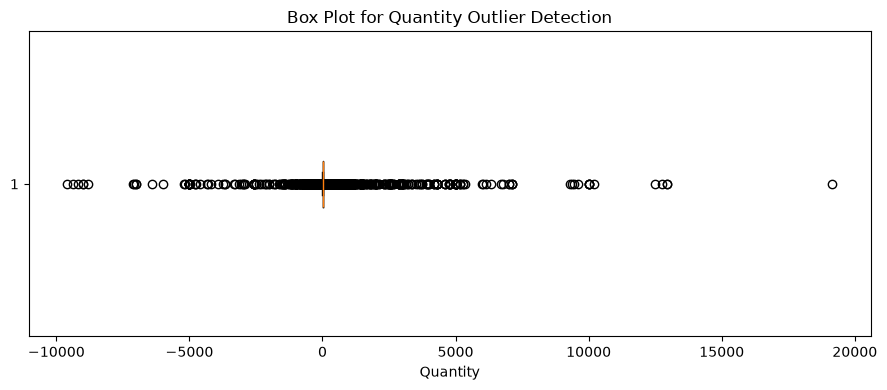

In [10]:
# Step 3: Implement the Concept

# Select the Quantity column and remove missing values
quantity_data = pd.to_numeric(
    df["Quantity"], errors="coerce"
).dropna()

# Calculate Q1, Q3, and IQR
q1 = quantity_data.quantile(0.25)
q3 = quantity_data.quantile(0.75)
iqr = q3 - q1

# Calculate the lower and upper bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify possible outliers
outliers = quantity_data[
    (quantity_data < lower_bound) |
    (quantity_data > upper_bound)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Possible Outliers:", len(outliers))

print("Sample Possible Outliers:")
display(outliers.head(10))

# Visualize possible outliers using a box plot
plt.figure(figsize=(9, 4))
plt.boxplot(quantity_data, vert=False)
plt.title("Box Plot for Quantity Outlier Detection")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Data

`pd.to_numeric()` converts the Quantity values into numeric data, and `dropna()` removes missing values.

### 2. Calculate the IQR

- Q1 represents the 25th percentile.
- Q3 represents the 75th percentile.
- IQR = Q3 − Q1.

### 3. Calculate the Bounds

- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Values outside these bounds are flagged as possible outliers.

### 4. Create the Box Plot

`plt.boxplot()` displays the distribution of Quantity. Individual points beyond the whiskers may indicate possible outliers.

### How to Interpret the Output

- The box shows the middle 50% of the data.
- The line inside the box represents the median.
- Points beyond the whiskers may be potential outliers.
- The IQR method and box plot use the same quartile-based rule here, so their flagged observations should generally agree.

### Where It Is Used in AI/ML or Data Analytics

Univariate outlier detection is useful for examining individual features, finding unusual transactions, and preparing data for machine learning.

### Observation

Record the IQR bounds and number of possible outliers. Inspect some flagged values and consider whether they are genuine transactions or possible data-quality issues.

Do not automatically remove the flagged values.

# Topic 5: Multivariate Outliers

## Step 1: Understand the Concept

A multivariate outlier is an observation that appears unusual when two or more variables are analyzed together.

### Example

Consider two variables in an online retail dataset:

- Quantity: Number of products purchased
- Price: Price per product

A transaction may have an unusual combination of quantity and price, even when each value does not appear extreme when examined separately.

### Why Do Multivariate Outliers Occur?

1. Unusual combinations of numerical values.
2. Unexpected customer purchasing behavior.
3. Data collection or entry errors.
4. Rare but genuine business transactions.

### Why Is It Important?

Multivariate outlier detection helps identify unusual relationships between variables that may not be visible when analyzing each column independently.

## Step 2: Demonstrate the Concept

### Simple Example

| Transaction | Quantity | Price | Interpretation |
|---|---:|---:|---|
| A | 2 | 10 | Possible typical transaction |
| B | 3 | 12 | Possible typical transaction |
| C | 2 | 500 | Unusually high price |
| D | 100 | 10 | Unusually high quantity |

These values are illustrative examples, not actual findings from the dataset.

### Real-World Example

A retail transaction with a large quantity and an unusual price may need further investigation.

### Business Example

A business analyst can compare quantity and price together to identify unusual transactions and verify product or invoice details.

### AI/ML Use Case

Multivariate outlier detection is useful in anomaly detection, fraud investigation, and identifying unusual patterns in multiple features.

### Important Note

A scatter plot can help visualize relationships between two variables, but a visual pattern alone does not prove that a transaction is incorrect.

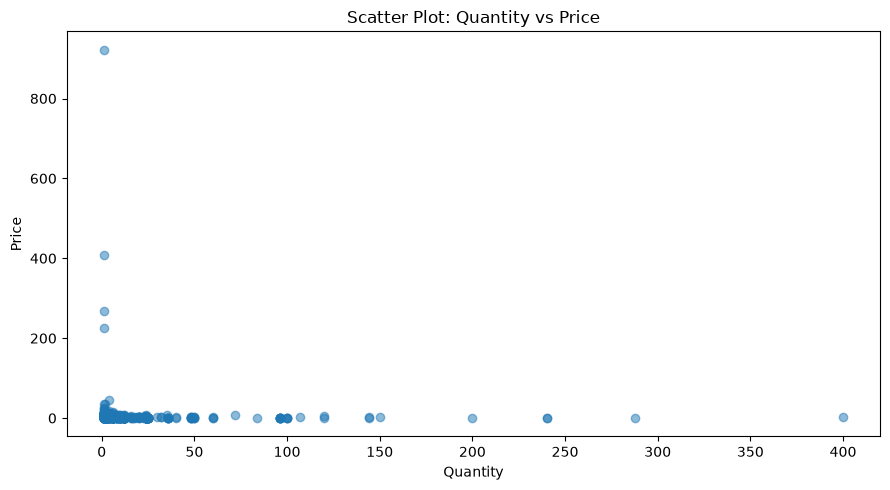

Number of transactions analyzed: 513132


In [11]:
# Step 3: Implement the Concept

# Select Quantity and Price
multivariate_data = df[["Quantity", "Price"]].copy()

# Convert both columns to numeric values
for column in ["Quantity", "Price"]:
    multivariate_data[column] = pd.to_numeric(
        multivariate_data[column],
        errors="coerce"
    )

# Remove missing and non-finite values
multivariate_data = multivariate_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Keep non-negative values for this visualization
multivariate_data = multivariate_data[
    (multivariate_data["Quantity"] >= 0) &
    (multivariate_data["Price"] >= 0)
]

# Sample rows if the dataset is large
plot_data = multivariate_data.sample(
    n=min(1000, len(multivariate_data)),
    random_state=42
)

# Visualize the relationship between Quantity and Price
plt.figure(figsize=(9, 5))
plt.scatter(
    plot_data["Quantity"],
    plot_data["Price"],
    alpha=0.5
)
plt.title("Scatter Plot: Quantity vs Price")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

print("Number of transactions analyzed:", len(multivariate_data))

## Code Explanation

### 1. Select Two Variables

The code selects `Quantity` and `Price` so that both features can be analyzed together.

### 2. Clean the Data

`pd.to_numeric()` converts the columns to numeric values. Missing and infinite values are removed, and non-negative values are retained for this visualization.

### 3. Sample the Data

`sample()` selects up to 1,000 rows to make the scatter plot easier to read when the dataset is large.

### 4. Create the Scatter Plot

`plt.scatter()` displays each transaction as a point.

- X-axis: Quantity
- Y-axis: Price
- Points far from the main pattern may deserve further investigation.

### Where It Is Used in AI/ML or Data Analytics

Scatter plots help analysts explore relationships between features and visually identify potentially unusual combinations before further anomaly detection.

### Observation

Describe whether the points form a main cluster and whether any points appear far away from it.

**Limitation:** This scatter plot visualizes possible multivariate outliers; it does not automatically classify or confirm them. A formal multivariate method can be added if required.

# Topic 6: Z-Score Method

## Step 1: Understand the Concept

The Z-Score method is a statistical technique used to identify values that are unusually far from the mean.

It measures how many standard deviations a value is away from the mean.

### Formula

Z-Score = (X − Mean) / Standard Deviation

Where:

- X: Individual data value
- Mean: Average of the data
- Standard Deviation: Measure of how spread out the values are

### Common Rule

A value with an absolute Z-Score greater than 3 is often flagged as a possible outlier.

### Why Is It Important?

The Z-Score method helps identify unusually high or low numerical values during data analysis and preprocessing.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the values 10, 12, 11, 13, and 50.

The value 50 is much higher than the other values and may receive a high positive Z-Score.

### Real-World Example

In online retail, a transaction with an unusually high product quantity may be flagged for investigation.

### Business Example

A retail analyst can use Z-Scores to identify unusually high product prices or quantities and investigate their causes.

### AI/ML Use Case

Z-Score analysis can help detect unusual numerical values before training machine learning models.

### Important Note

The common threshold of 3 is a guideline, not a universal rule. Z-Scores can be affected by extreme values and may be less suitable for highly skewed data.

In [12]:
# Step 3: Implement the Concept

# Select the Quantity column and remove invalid values
quantity_data = pd.to_numeric(
    df["Quantity"], errors="coerce"
).replace([np.inf, -np.inf], np.nan).dropna()

# Calculate the mean and standard deviation
mean_quantity = quantity_data.mean()
std_quantity = quantity_data.std()

print("Mean Quantity:", mean_quantity)
print("Standard Deviation:", std_quantity)

# Calculate Z-Scores
if std_quantity > 0:
    z_scores = (
        (quantity_data - mean_quantity) / std_quantity
    )

    # Identify possible outliers using |Z-Score| > 3
    z_score_outliers = quantity_data[
        z_scores.abs() > 3
    ]

    print("Number of Possible Outliers:", len(z_score_outliers))
    print("Sample Possible Outliers:")
    display(z_score_outliers.head(10))
else:
    print("Z-Scores cannot be calculated because the standard deviation is zero.")

Mean Quantity: 10.337667305470815
Standard Deviation: 107.42411026879778
Number of Possible Outliers: 1345
Sample Possible Outliers:


217      576
575      800
3162   -1043
3572     450
4296    -770
4538    -720
4793     480
6443     480
6555     954
6556    -954
Name: Quantity, dtype: int64

## Code Explanation

### 1. Prepare the Data

The code converts `Quantity` to numeric values and removes missing and infinite values.

### 2. Calculate Mean and Standard Deviation

- `mean()` calculates the average quantity.
- `std()` calculates the standard deviation.

### 3. Calculate Z-Scores

The code subtracts the mean from each value and divides the result by the standard deviation.

### 4. Identify Possible Outliers

`z_scores.abs() > 3` flags values whose absolute Z-Score exceeds 3.

A positive Z-Score indicates a value above the mean, while a negative Z-Score indicates a value below the mean.

### Where It Is Used in AI/ML or Data Analytics

Z-Scores can help identify unusual numerical observations, standardize features, and support data-quality checks.

### Observation

Record the mean, standard deviation, and number of flagged values. Compare the results with the IQR method and investigate the flagged transactions before deciding how to handle them.

**Note:** The Z-Score method assumes the mean and standard deviation are useful summaries of the data. For highly skewed retail quantities, the IQR method may be more robust.

# Topic 7: Box Plot for Outlier Detection

## Step 1: Understand the Concept

A box plot is a visualization technique used to understand the distribution of numerical data and identify possible outliers.

### Main Components

1. **Minimum and Maximum Whiskers:** Show the range of non-outlier values according to the box plot rule.
2. **First Quartile (Q1):** The 25th percentile.
3. **Median (Q2):** The 50th percentile.
4. **Third Quartile (Q3):** The 75th percentile.
5. **Outlier Points:** Values plotted separately beyond the whiskers.

### IQR Rule

IQR = Q3 − Q1

Lower Bound = Q1 − 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are commonly flagged as possible outliers.

### Why Is It Important?

Box plots make it easier to understand data spread, compare distributions, and visually inspect unusual values.

## Step 2: Demonstrate the Concept

### Simple Example

Consider product quantities:

`2, 3, 4, 5, 6, 7, 100`

Most values are between 2 and 7, while 100 is much larger. A box plot may display 100 as a possible outlier.

### Real-World Example

An online retail dataset may contain a few transactions with unusually large quantities compared with typical purchases.

### Business Example

A business analyst can use box plots to compare product prices and investigate unusually expensive items.

### AI/ML Use Case

Box plots help analysts inspect numerical features during exploratory data analysis before model training.

### Important Note

A point beyond the whiskers is a possible statistical outlier, not necessarily an error. Verify the transaction before changing the data.

Q1: 1.0
Median: 3.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of Possible Outliers: 57870


C:\Users\hh213\AppData\Local\Temp\ipykernel_10220\3530373827.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


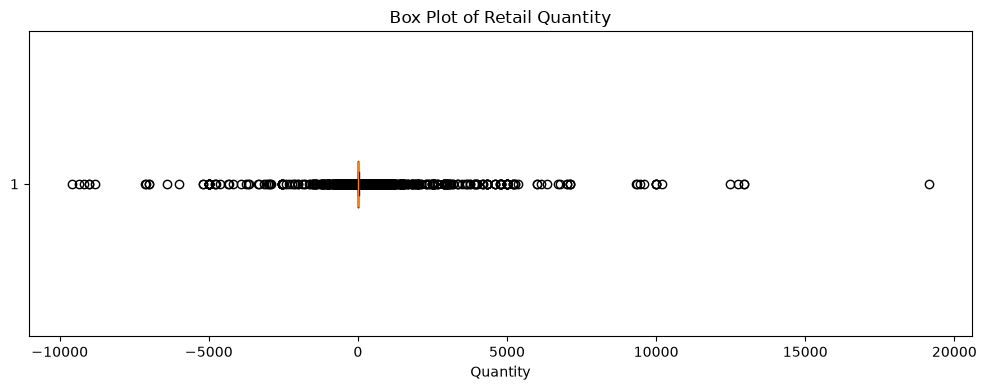

In [13]:
# Step 3: Implement the Concept

# Prepare the Quantity column
quantity_data = pd.to_numeric(
    df["Quantity"], errors="coerce"
).replace([np.inf, -np.inf], np.nan).dropna()

# Calculate quartiles and IQR
q1 = quantity_data.quantile(0.25)
median = quantity_data.median()
q3 = quantity_data.quantile(0.75)
iqr = q3 - q1

# Calculate outlier boundaries
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify possible outliers
outliers = quantity_data[
    (quantity_data < lower_bound) |
    (quantity_data > upper_bound)
]

print("Q1:", q1)
print("Median:", median)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Possible Outliers:", len(outliers))

# Create a box plot
plt.figure(figsize=(10, 4))
plt.boxplot(
    quantity_data,
    vert=False,
    showfliers=True
)
plt.title("Box Plot of Retail Quantity")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Prepare the Data

The code converts Quantity values to numeric format and removes missing or infinite values.

### 2. Calculate Quartiles

- `quantile(0.25)` calculates Q1.
- `median()` calculates the median.
- `quantile(0.75)` calculates Q3.
- IQR is calculated by subtracting Q1 from Q3.

### 3. Identify Possible Outliers

The lower and upper bounds are calculated using the IQR rule. Values outside these limits are counted as possible outliers.

### 4. Create the Box Plot

`plt.boxplot()` displays the distribution of Quantity.

- The box represents the middle 50% of observations.
- The line inside the box represents the median.
- The whiskers show the non-outlier range according to the plotting rule.
- Separate points may indicate possible outliers.

### Where It Is Used in AI/ML or Data Analytics

Box plots are useful for exploratory data analysis, comparing numerical distributions, and identifying values that need further investigation.

### Observation

Record the median, IQR, and number of possible outliers. Check whether the unusual values are genuine retail transactions or possible data errors.

Do not automatically remove outliers based only on the box plot.

# Topic 8: Scatter Plot for Outlier Detection

## Step 1: Understand the Concept

A scatter plot is a visualization technique used to display the relationship between two numerical variables.

Each point represents one observation in the dataset.

### Main Components

- **X-axis:** Represents the first numerical variable.
- **Y-axis:** Represents the second numerical variable.
- **Points:** Represent individual observations.
- **Unusual Points:** Points far away from the main pattern may be potential outliers.

### Why Is It Important?

A scatter plot helps identify unusual combinations of values and understand relationships between numerical features.

### Limitation

A scatter plot can help visually identify possible outliers, but it does not automatically confirm or classify them.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following transactions:

| Transaction | Quantity | Price |
|---|---:|---:|
| A | 2 | 10 |
| B | 3 | 12 |
| C | 4 | 11 |
| D | 5 | 13 |
| E | 100 | 10 |

Transaction E has a much larger quantity than the other transactions. In a scatter plot, it may appear far away from the main group.

### Real-World Example

An online retail company can plot product quantity against unit price to inspect unusual transactions.

### Business Example

Analysts can use scatter plots to investigate bulk purchases, unusual prices, and unexpected combinations of transaction values.

### AI/ML Use Case

Scatter plots support exploratory data analysis and help identify observations that may need further anomaly detection.

### Important Note

An unusual point may represent a genuine bulk order or a data error. Additional evidence is required before changing it.

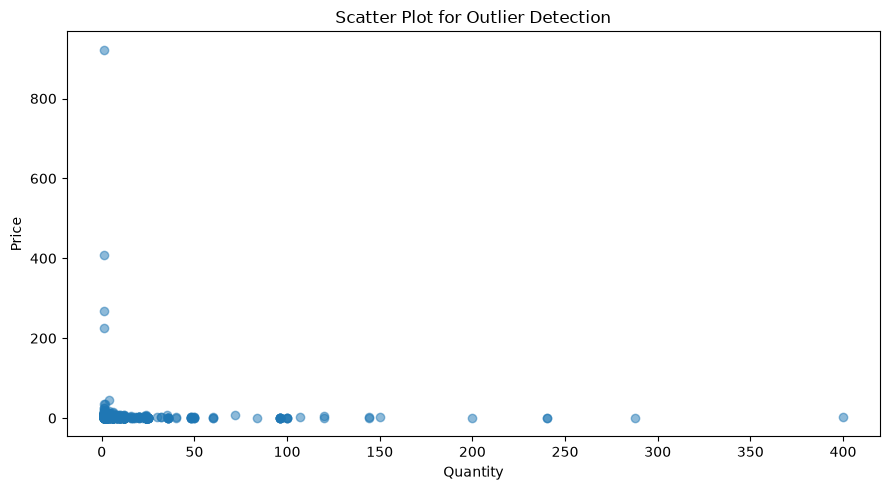

Total valid transactions: 513132
Transactions plotted: 1000


In [14]:
# Step 3: Implement the Concept

# Select Quantity and Price
scatter_data = df[["Quantity", "Price"]].copy()

# Convert both columns to numeric values
for column in ["Quantity", "Price"]:
    scatter_data[column] = pd.to_numeric(
        scatter_data[column],
        errors="coerce"
    )

# Remove missing and infinite values
scatter_data = scatter_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Keep non-negative values for this visualization
scatter_data = scatter_data[
    (scatter_data["Quantity"] >= 0) &
    (scatter_data["Price"] >= 0)
]

# Sample rows to improve readability
plot_data = scatter_data.sample(
    n=min(1000, len(scatter_data)),
    random_state=42
)

# Create the scatter plot
plt.figure(figsize=(9, 5))
plt.scatter(
    plot_data["Quantity"],
    plot_data["Price"],
    alpha=0.5
)

plt.title("Scatter Plot for Outlier Detection")
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

print("Total valid transactions:", len(scatter_data))
print("Transactions plotted:", len(plot_data))

## Code Explanation

### 1. Select Numerical Features

The code selects `Quantity` and `Price` to examine their relationship.

### 2. Clean the Data

`pd.to_numeric()` converts values to numbers. Missing and infinite values are removed, and negative values are excluded from this particular visualization.

### 3. Sample the Data

`sample()` selects up to 1,000 transactions so the graph is easier to inspect.

### 4. Create the Scatter Plot

`plt.scatter()` plots Quantity on the X-axis and Price on the Y-axis.

Points far from the main cluster may represent unusual combinations of values and should be investigated.

### Where It Is Used in AI/ML or Data Analytics

Scatter plots help analysts explore relationships between features, identify unusual observations visually, and decide which records need further investigation.

### Observation

After running the code, note whether the points form a main cluster and whether any points appear far from it. Record a possible explanation for one unusual point if you observe one.

Do not assume that every distant point is an error. This graph is a visual screening technique, not a formal outlier detector.

# Topic 9: Handling Outliers

## Step 1: Understand the Concept

After detecting outliers, we must investigate them and decide how to handle them.

### Common Ways to Handle Outliers

1. **Retain:** Keep the value if it represents a genuine observation.
2. **Correct:** Fix the value if a data-entry or measurement error is confirmed and the correct value is known.
3. **Remove:** Remove the observation only when it is confirmed to be invalid and cannot be corrected, or when there is a justified analysis requirement.
4. **Transform:** Apply a suitable transformation, such as a logarithmic transformation, when it is appropriate for the analysis.
5. **Cap or Winsorize:** Replace extreme values with selected limits when the method is justified and documented.

### Why Is It Important?

Incorrect handling of outliers can remove useful information, distort statistical results, and negatively affect machine learning models.

### Important Rule

Never remove an outlier automatically just because it is unusually high or low.

## Step 2: Demonstrate the Concept

### Simple Example

| Observation | Possible Reason | Possible Action |
|---|---|---|
| Quantity = 500 | Genuine bulk order | Retain |
| Quantity entered as 5000 instead of 50 | Confirmed entry error | Correct |
| Quantity = -999 due to a confirmed invalid record | Invalid transaction | Correct or remove based on evidence |
| Highly skewed price distribution | Natural variation | Consider transformation if appropriate |

These are illustrative examples. The correct action depends on the available evidence.

### Real-World Example

A large order may be a valid purchase from a business customer. Removing it could cause the company to underestimate demand.

### Business Example

A retail analyst should verify invoice details, product information, and transaction records before correcting or removing unusual values.

### AI/ML Use Case

Handling outliers appropriately helps maintain data quality and can improve model reliability.

### Decision Checklist

- Is the value a confirmed error?
- Can the correct value be recovered?
- Is the observation genuine but unusual?
- Will changing it affect the analysis?
- Is the decision documented?

In [15]:
# Step 3: Implement the Concept

# Create a review dataset using Quantity
quantity_review = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

# Calculate IQR bounds
q1 = quantity_review.quantile(0.25)
q3 = quantity_review.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Identify possible outliers
outlier_mask = (
    (quantity_review < lower_bound) |
    (quantity_review > upper_bound)
)

# Keep the original dataset unchanged
outlier_review = df.loc[outlier_mask].copy()

# Add a review status column
outlier_review["Review Status"] = "Needs Investigation"

print("Possible outliers:", len(outlier_review))
print("Original dataset shape:", df.shape)

# Display records for investigation
display(
    outlier_review[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Country", "Review Status"]
    ].head(10)
)

Possible outliers: 57870
Original dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,Price,Country,Review Status
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,United Kingdom,Needs Investigation
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,United Kingdom,Needs Investigation
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,1.65,United Kingdom,Needs Investigation
6,489434,21871,SAVE THE PLANET MUG,24,1.25,United Kingdom,Needs Investigation
10,489435,22195,HEART MEASURING SPOONS LARGE,24,1.65,United Kingdom,Needs Investigation
30,489436,22111,SCOTTIE DOG HOT WATER BOTTLE,24,4.25,United Kingdom,Needs Investigation
54,489438,21329,DINOSAURS WRITING SET,28,0.98,United Kingdom,Needs Investigation
55,489438,21252,SET OF MEADOW FLOWER STICKERS,30,1.69,United Kingdom,Needs Investigation
56,489438,21100,CHARLIE AND LOLA CHARLOTTE BAG,30,1.15,United Kingdom,Needs Investigation
57,489438,21033,JUMBO BAG CHARLIE AND LOLA TOYS,30,2.00,United Kingdom,Needs Investigation


## Code Explanation

### 1. Calculate IQR Bounds

The code calculates Q1, Q3, and IQR to establish the lower and upper limits.

### 2. Identify Possible Outliers

The Boolean mask identifies Quantity values outside the calculated limits.

### 3. Create a Review Dataset

`df.loc[outlier_mask].copy()` creates a separate copy of the flagged records. The original `df` is not modified.

### 4. Add a Review Status

The `Review Status` column marks the records as requiring investigation. It does not claim that they are errors.

### Where It Is Used in AI/ML or Data Analytics

A separate review dataset helps data analysts verify unusual observations, document decisions, and preserve the original data for reproducibility.

### Observation

Inspect the displayed records and choose a suitable action only when supporting evidence is available:

- Retain genuine transactions.
- Correct confirmed errors when the correct value is known.
- Remove confirmed invalid records only when justified.
- Consider transformation or capping when appropriate for the analysis.

**Important:** This code only flags records for review. It does not automatically correct, remove, or transform any observations.

In [16]:
# Document outlier investigation decisions

outlier_decisions = outlier_review[
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
].head(10).copy()

# Add columns to document the investigation
outlier_decisions["Reason"] = "Needs investigation"
outlier_decisions["Decision"] = "Pending review"
outlier_decisions["Justification"] = "Evidence not yet verified"

# Display the review table
display(outlier_decisions)

# Save the review table for documentation
outlier_decisions.to_csv(
    "outlier_decision_review.csv",
    index=False
)

print("Outlier decision review table created successfully.")

,Invoice,StockCode,Description,Quantity,Price,Reason,Decision,Justification
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,Needs investigation,Pending review,Evidence not yet verified
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,Needs investigation,Pending review,Evidence not yet verified
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,1.65,Needs investigation,Pending review,Evidence not yet verified
6,489434,21871,SAVE THE PLANET MUG,24,1.25,Needs investigation,Pending review,Evidence not yet verified
10,489435,22195,HEART MEASURING SPOONS LARGE,24,1.65,Needs investigation,Pending review,Evidence not yet verified
30,489436,22111,SCOTTIE DOG HOT WATER BOTTLE,24,4.25,Needs investigation,Pending review,Evidence not yet verified
54,489438,21329,DINOSAURS WRITING SET,28,0.98,Needs investigation,Pending review,Evidence not yet verified
55,489438,21252,SET OF MEADOW FLOWER STICKERS,30,1.69,Needs investigation,Pending review,Evidence not yet verified
56,489438,21100,CHARLIE AND LOLA CHARLOTTE BAG,30,1.15,Needs investigation,Pending review,Evidence not yet verified
57,489438,21033,JUMBO BAG CHARLIE AND LOLA TOYS,30,2.00,Needs investigation,Pending review,Evidence not yet verified


Outlier decision review table created successfully.


## Explanation: Documenting Outlier Decisions

### 1. Select the Required Columns

The code selects invoice, product, quantity, price, and country details to help investigate each possible outlier.

### 2. Create a Separate Review Table

The `.copy()` method creates a separate table. The original dataset remains unchanged.

### 3. Add Investigation Columns

- **Observation Type:** Record whether the observation is genuine, a confirmed data-entry error, or unusual but valid.
- **Reason:** Explain why the value was flagged and what evidence was checked.
- **Decision:** Record whether the value should be retained, corrected, removed, transformed, or capped.
- **Justification:** Explain why the selected action is appropriate.

### 4. Review Before Making a Decision

The code uses default labels such as `Not yet verified` and `Pending Investigation`. These are placeholders, not conclusions about the data.

### 5. Where It Is Used in AI/ML or Data Analytics

Documenting outlier decisions improves data quality, transparency, reproducibility, and trust in the dataset used for analysis or model training.